<a href="https://colab.research.google.com/github/Krishna9423-wagh/Image-Pixel-Manipulator-Synthetic-Images-/blob/main/image_pixel_manipulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import numpy as np
import matplotlib.pyplot as plt

shape: (200, 200, 3) | dtype: uint8


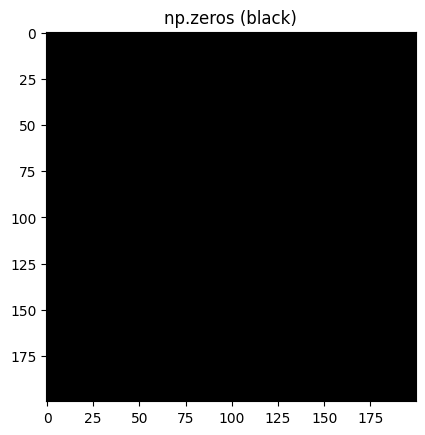

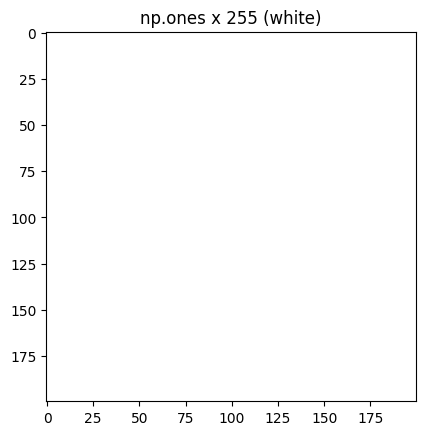

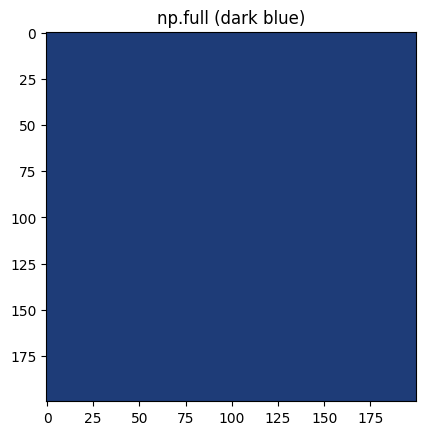

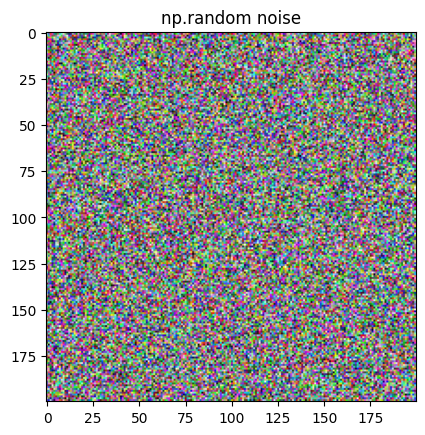

In [32]:
black = np.zeros((200, 200, 3), dtype=np.uint8)
print("shape:", black.shape, "| dtype:", black.dtype)
plt.imshow(black); plt.title("np.zeros (black)"); plt.show()

white = np.ones((200, 200, 3), dtype=np.uint8) * 255
plt.imshow(white); plt.title("np.ones x 255 (white)"); plt.show()

img = np.full((200, 200, 3), [30, 60, 120], dtype=np.uint8)
plt.imshow(img); plt.title("np.full (dark blue)"); plt.show()

noise = np.random.randint(0, 256, (200, 200, 3), dtype=np.uint8)
plt.imshow(noise); plt.title("np.random noise"); plt.show()

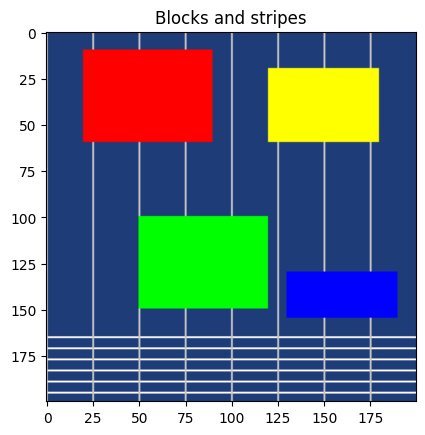

In [33]:
img[165:200:6, :] = [255, 255, 255]
img[:, 0:200:25] = [200, 200, 200]

img[10:60, 20:90]     = [255, 0, 0]
img[100:150, 50:120]  = [0, 255, 0]
img[130:155, 130:190] = [0, 0, 255]
img[20:60, 120:180, 0] = 255
img[20:60, 120:180, 1] = 255
img[20:60, 120:180, 2] = 0

plt.imshow(img); plt.title("Blocks and stripes"); plt.show()

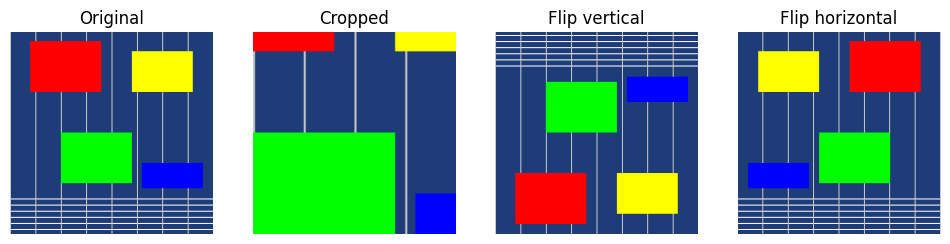

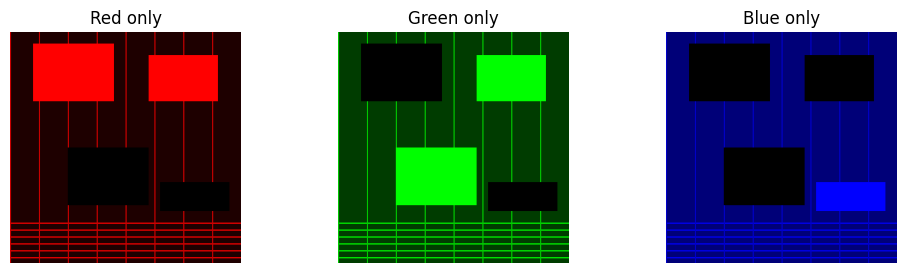

In [34]:
cropped = img[50:150, 50:150].copy()
flip_v  = img[::-1]
flip_h  = img[:, ::-1]

plt.figure(figsize=(12, 3))
for i, (im, t) in enumerate([(img, "Original"), (cropped, "Cropped"),
                             (flip_v, "Flip vertical"), (flip_h, "Flip horizontal")], 1):
    plt.subplot(1, 4, i); plt.imshow(im); plt.title(t); plt.axis("off")
plt.show()

names = ["Red", "Green", "Blue"]
plt.figure(figsize=(12, 3))
for c in range(3):
    only = np.zeros((200, 200, 3), dtype=np.uint8)
    only[:, :, c] = img[:, :, c]
    plt.subplot(1, 3, c + 1); plt.imshow(only); plt.title(names[c] + " only"); plt.axis("off")
plt.show()

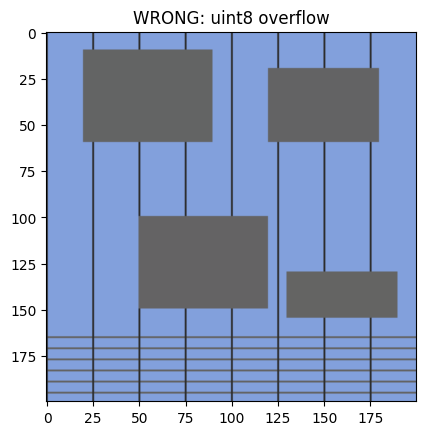

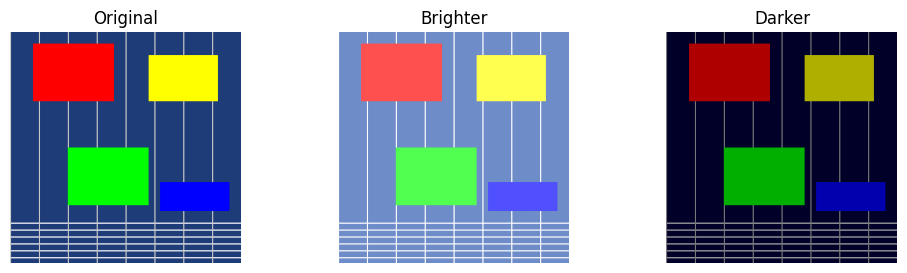

Bright pixels: 1152 out of 40000


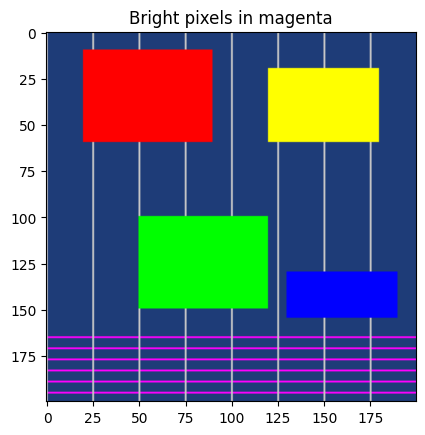

In [35]:
wrong = img + 100
plt.imshow(wrong); plt.title("WRONG: uint8 overflow"); plt.show()

f = img.astype(np.float32)

bright = f + 80
bright[bright > 255] = 255
bright = bright.astype(np.uint8)

dark = f - 80
dark[dark < 0] = 0
dark = dark.astype(np.uint8)

plt.figure(figsize=(12, 3))
for i, (im, t) in enumerate([(img, "Original"), (bright, "Brighter"), (dark, "Darker")], 1):
    plt.subplot(1, 3, i); plt.imshow(im); plt.title(t); plt.axis("off")
plt.show()


mask = (img[:, :, 0] > 200) & (img[:, :, 1] > 200) & (img[:, :, 2] > 200)
print("Bright pixels:", mask.sum(), "out of", mask.size)

highlighted = img.copy()
highlighted[mask] = [255, 0, 255]
plt.imshow(highlighted); plt.title("Bright pixels in magenta"); plt.show()

uint8  : uint8 120000 bytes
float32: float32 480000 bytes
float32 uses 4 x more memory


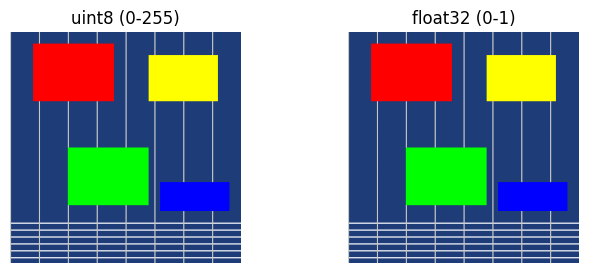

In [36]:
 img_f32 = img.astype(np.float32)

print("uint8  :", img.dtype, img.nbytes, "bytes")
print("float32:", img_f32.dtype, img_f32.nbytes, "bytes")
print("float32 uses", img_f32.nbytes // img.nbytes, "x more memory")

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1); plt.imshow(img);              plt.title("uint8 (0-255)"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(img_f32 / 255);    plt.title("float32 (0-1)"); plt.axis("off")
plt.show()